# Floating-Point Arithmetic and Numerical Stability

**AI Mathematics · 4. Numerical Computation**

Learn why mathematically equivalent formulas may behave differently on a computer and how to avoid common numerical failures.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Recognize rounding, overflow, underflow, and cancellation.
- Use stable implementations for softmax and logarithms.
- Interpret conditioning and choose safe comparisons.

In [1]:
import numpy as np

## 1. Floating-point values are approximations
Many decimal fractions cannot be represented exactly in binary floating point. Tiny representation errors are normal; they become problematic when amplified by a calculation.

In [2]:
import numpy as np

print(0.1 + 0.2)
print((0.1 + 0.2) == 0.3)
print(np.isclose(0.1 + 0.2, 0.3))

# Compare with a tolerance appropriate to the scale and application.

0.30000000000000004
False
True


## 2. Cancellation and summation
Subtracting nearly equal numbers can destroy significant digits. Summing many values of different magnitudes can also depend on order. Use numerically stable algorithms and higher precision when the problem requires it.

In [3]:
a = 1e16
b = 1.0
c = -1e16
print("(a + b) + c:", (a + b) + c)
print("a + (b + c):", a + (b + c))
print("NumPy sum:", np.sum([a, b, c]))

(a + b) + c: 0.0
a + (b + c): 0.0
NumPy sum: 0.0


## 3. Overflow, underflow, and log-sum-exp
Exponentials of large positive values may overflow; exponentials of very negative values may underflow to zero. Softmax should subtract the largest logit before exponentiation. Cross-entropy is usually more stable when calculated directly from logits.

In [4]:
def stable_softmax(logits):
    logits = np.asarray(logits, dtype=float)
    shifted = logits - np.max(logits)
    e = np.exp(shifted)
    return e / e.sum()

logits = np.array([1000.0, 1001.0, 999.0])
print(stable_softmax(logits))

# Stable log-sum-exp
def logsumexp(x):
    x = np.asarray(x, dtype=float)
    m = np.max(x)
    return m + np.log(np.sum(np.exp(x - m)))
print(logsumexp(logits))

[0.24472847 0.66524096 0.09003057]
1001.4076059644444


## 4. Conditioning
Conditioning describes sensitivity of a problem’s solution to small input changes. A matrix with a large condition number can make a linear solve sensitive to rounding and measurement error. Stability is about the algorithm; conditioning is about the mathematical problem.

In [5]:
A_good = np.array([[2.0, 0.0], [0.0, 1.0]])
A_ill = np.array([[1.0, 1.0], [1.0, 1.000001]])
print("condition number, good:", np.linalg.cond(A_good))
print("condition number, near-dependent:", np.linalg.cond(A_ill))

condition number, good: 2.0
condition number, near-dependent: 4000002.0005977214


## 5. Practical numerical habits
- Compare floats with `np.isclose`/`np.allclose`, not exact equality.
- Scale features and parameters when their magnitudes differ dramatically.
- Avoid explicit matrix inversion for solves.
- Monitor loss, gradients, and activations for NaN or infinity.
- A smaller error tolerance is not always better if roundoff dominates.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: numerically stable Softmax

Softmax converts logits into a probability vector. The direct expression \(e^{z_i}/\sum_j e^{z_j}\) can overflow when logits are large. Subtracting the maximum logit leaves the exact mathematical probabilities unchanged but keeps the largest exponent equal to 1. This is a common stability trick in classification and attention implementations.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
def viz_softmax_naive(z):
    z = np.asarray(z, dtype=float)
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        e = np.exp(z)
        return e/e.sum()
def viz_softmax_stable(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z-np.max(z))
    return e/e.sum()
viz_softmax_logits = np.array([1000.0, 1001.0, 998.0])
print("naive softmax:", viz_softmax_naive(viz_softmax_logits))
print("stable softmax:", np.round(viz_softmax_stable(viz_softmax_logits), 6))
display(pd.DataFrame({"logit": viz_softmax_logits, "stable probability": viz_softmax_stable(viz_softmax_logits)}))

naive softmax: [nan nan nan]
stable softmax: [0.259496 0.705385 0.035119]


,logit,stable probability
0,1000.0,0.259496
1,1001.0,0.705385
2,998.0,0.035119


### Conditioning: small input errors can become large output errors

The condition number describes how sensitive a mathematical problem is to small perturbations. It is a property of the problem and representation, not necessarily a bug in the algorithm. Ill-conditioned systems may lose reliable digits even when solved with a good method.

13_floating_point_and_numerical_stability.ipynb:cell16:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,smallest diagonal,condition number,solution norm
0,1.000,1.000000e+00,1.414000e+00
1,0.100,1.000000e+01,1.005000e+01
2,0.010,1.000000e+02,1.000050e+02
3,0.001,1.000000e+03,1.000000e+03
4,0.000,1.000000e+04,1.000000e+04
5,0.000,1.000000e+05,1.000000e+05
6,0.000,1.000000e+06,1.000000e+06
7,0.000,1.000000e+07,1.000000e+07
8,0.000,1.000000e+08,1.000000e+08
9,0.000,1.000000e+09,1.000000e+09


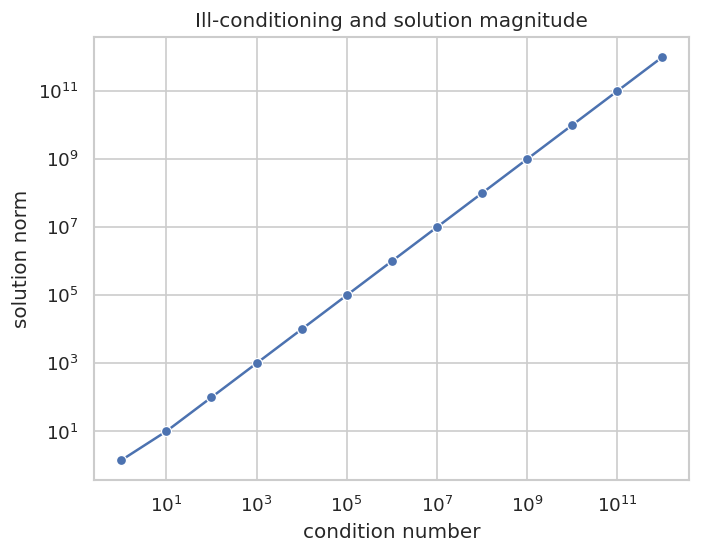

In [7]:
viz_cond_exponents = np.arange(0, 13)
viz_cond_rows = []
for viz_cond_exp in viz_cond_exponents:
    viz_cond_A = np.diag([1.0, 10.0**(-viz_cond_exp)])
    viz_cond_b = np.array([1.0, 1.0])
    viz_cond_x = np.linalg.solve(viz_cond_A, viz_cond_b)
    viz_cond_rows.append({"smallest diagonal": 10.0**(-viz_cond_exp), "condition number": np.linalg.cond(viz_cond_A), "solution norm": np.linalg.norm(viz_cond_x)})
viz_cond_df = pd.DataFrame(viz_cond_rows)
display(viz_cond_df.round(3))
sns.lineplot(data=viz_cond_df, x="condition number", y="solution norm", marker="o")
plt.xscale("log"); plt.yscale("log"); plt.title("Ill-conditioning and solution magnitude"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Implement stable softmax for logits [10000, 10001].

In [8]:
x = np.array([10000.0, 10001.0])
e = np.exp(x - x.max())
print(e / e.sum())

[0.26894142 0.73105858]


### Exercise 2
Exercise 2: Check whether two arrays are approximately equal.

In [9]:
a = np.array([1.0, 1.0 + 1e-9])
b = np.array([1.0, 1.0])
print(np.allclose(a, b, atol=1e-8))

True


## Key takeaways
- Floating-point arithmetic is approximate, so exact equality can be misleading.
- Stabilize exponentials and logarithms with algebraically equivalent formulas.
- A poorly conditioned problem can be sensitive even when the chosen algorithm is stable.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.